函数总结

# Embedding：文本向量化

- `embeddings = make_embeddings()`

创建一个Embedding对象，用的是rag_config.py定义的函数

- embeddings.`embed_query()`

把字符串str变成向量list[float]

- embeddings.`embed_documents()`

把文档[str,str,str...]转化为向量列表[
    [0.12, 0.35, ],
    [0.23, 0.45,]
]

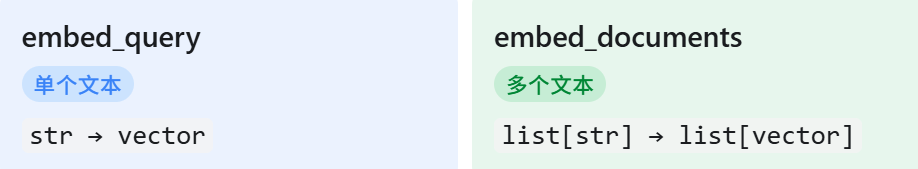

# Prompt：提示词模板

| 方法 | 入参形式 | 返回模板类型 | 含义说明 |
| --- | --- | --- | --- |
| PromptTemplate.from_template() | 字符串模板 | PromptTemplate | 普通纯文本提示词模板，**没有角色区分**，只做字符串拼接 |
| ChatPromptTemplate.from_template() | 字符串模板 | ChatPromptTemplate | 快捷写法，自动把这段文本包装成**单条 Human（用户）消息** |
| ChatPromptTemplate.from_messages() | 消息元组列表 `[("system","xxx"),("human","xxx")]` | ChatPromptTemplate | 多角色对话模板，可以自由组合 system /human/ai 多条消息 |

## PromptTemplate.from_template

只是把str转化成模版类型，适用于给llm下指令，不适合聊天

## ChatPromptTemplate.from_template()

也是把str转化成模版类型，但是会把模版包装成一条 Human 消息。可以理解为：

[

    ("human", "请回答下面的问题：{question}")

]

## ChatPromptTemplate.from_messages()

- 传入一个列表，包含多种消息。
```py
prompt = ChatPromptTemplate.from_messages(
    [
        ("system", "你是一个 Python 专家"),
        ("human", "{question}"),
        ("ai", "我来为你解答"),
    ]
)
```




# Rag From Scratch: Routing

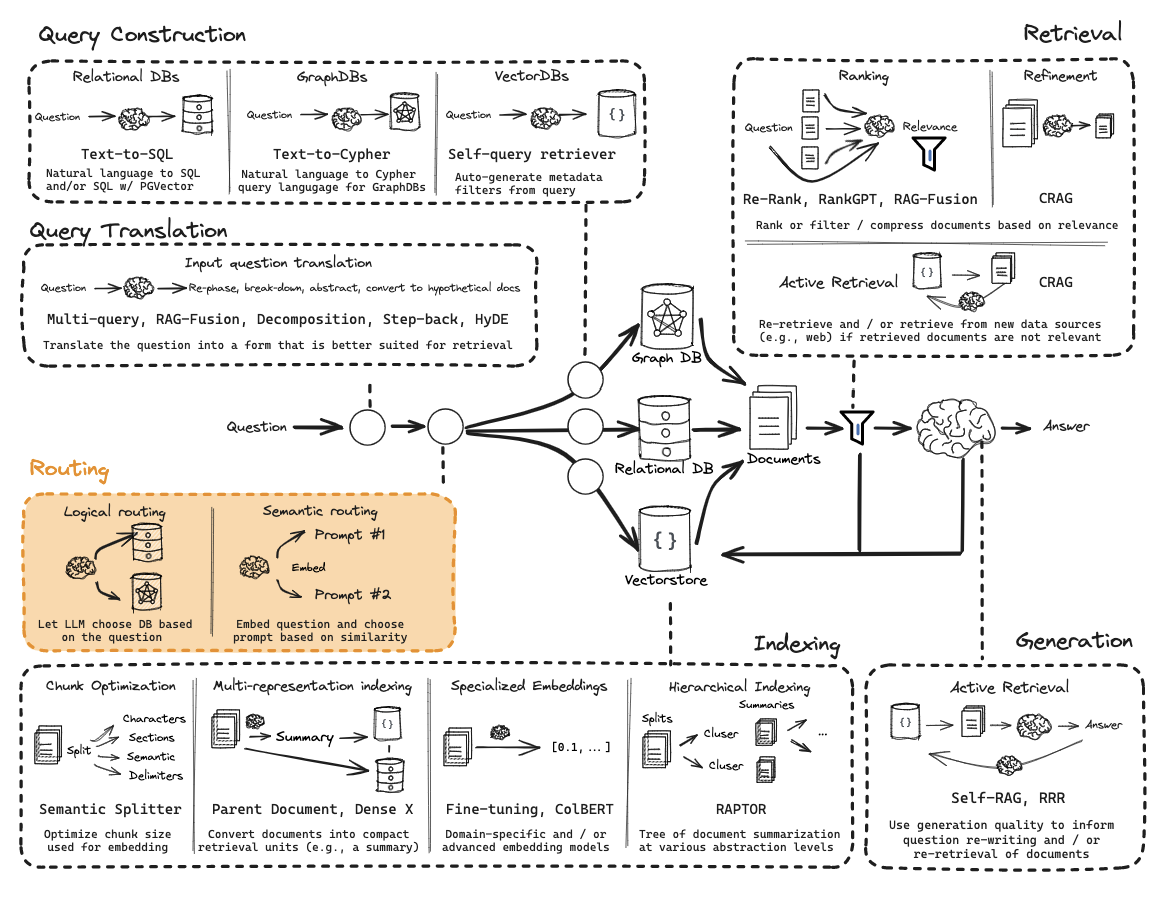



In [1]:
from rag_config import load_config, show_config

load_config()
show_config()  # Only show model names and whether a key is configured.


PARATERA_BASE_URL: https://llmapi.paratera.com/v1
PARATERA_CHAT_MODEL: Qwen3.8-Flash
PARATERA_EMBEDDING_MODEL: GLM-Embedding-3
PARATERA_API_KEY configured: True


| 概念 | 理解 |
|---|---|
| Runnable | 可以在管道执行的组件 |
| invoke() | 执行组件或链 |
| | | 将组件连接起来 |
| Chain | 多个组件组合形成的执行流程 |
| RunnableSequence | 按顺序执行的 Chain |
| router | 自定义的路由chain |

#  Logical 逻辑路由

Flow: 

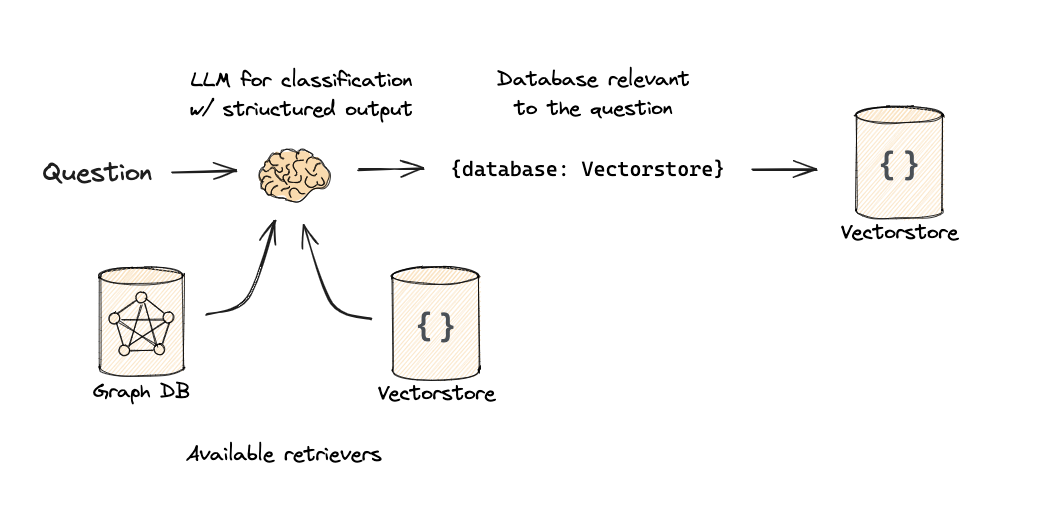

1. 用户提出问题。
2. LLM 判断问题应该使用哪个数据库。
3. LLM 输出结构化结果，例如 {database: Vectorstore}。
4. 系统根据这个结果选择向量数据库对应的 Retriever。
5. 由选中的 Retriever 检索相关文档。


In [ ]:
# 定义router ，定义路由规则
from langchain_core.prompts import ChatPromptTemplate
from rag_config import make_chat_model


from typing import Literal
from pydantic import BaseModel, Field

# Data model

# Route a user query to the most relevant datasource.
# 将用户查询路由至最匹配的数据源  
class RouteQuery(BaseModel):
    datasource: Literal["python_docs", "js_docs", "golang_docs"] = Field(
        ...,
        description="Given a user question choose which datasource would be most relevant for answering their question",
    )


# LLM with function call 
llm = make_chat_model(temperature=0) #降低生成结果的随机性，输出预测概率大的

# with_structured_output 结构化输出

# 让llm按照某个规定好的 Data model类输出。
# method表示使用模型的函数调用机制来实现结构化输出。
structured_llm = llm.with_structured_output(
    schema=RouteQuery, # 获取 RouteQuery 的 JSON Schema。用来规定 LLM 应该返回什么结构。
    method="function_calling"
    )

# Prompt 
system_templete = """You are an expert at routing a user question to the appropriate data source.

Based on the programming language the question is referring to, route it to the relevant data source."""

prompt = ChatPromptTemplate.from_messages(
    [
        ("system", system_templete), #告诉 LLM 分类规则
        ("human", "{question}"),
    ]
)

# Define router 
router = prompt | structured_llm    #经过llm输出一个Pydantic对象

print(router)
print(router.first)
# router链内部分为三个结构：
# first：Prompt：接收 question，生成 System + Human 消息,生成完整的chat prompt
# middle：LLM：绑定 RouteQuery Schema，调用模型
# last：Parser：将工具调用结果解析为 RouteQuery 对象

# 最终输出：RouteQuery(datasource="python_docs")

first=ChatPromptTemplate(input_variables=['question'], input_types={}, partial_variables={}, messages=[SystemMessagePromptTemplate(prompt=PromptTemplate(input_variables=[], input_types={}, partial_variables={}, template='You are an expert at routing a user question to the appropriate data source.\n\nBased on the programming language the question is referring to, route it to the relevant data source.'), additional_kwargs={}), HumanMessagePromptTemplate(prompt=PromptTemplate(input_variables=['question'], input_types={}, partial_variables={}, template='{question}'), additional_kwargs={})]) middle=[_ChatModelBinding(bound=ChatOpenAI(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7', 'langchain-openai': '1.7.3'}}, client=<openai.resources.chat.completions.completions.Completions object at 0x0000024C6A53DD30>, async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x0000024C6A75B2F0>, root_client=<openai.OpenAI object at 0x0000024C6A53E

# Pydantic

是一个 Python 数据验证和数据结构管理库。 它主要解决的问题是：规定数据应该长什么样，并自动检查数据是否符合要求。

- from pydantic import BaseModel
- from pydantic import Field



## BaseModel

BaseModel 是 Pydantic 提供的基类。

继承它，可以定义一个具有`明确字段和数据类型`的数据模型。
```bash
from pydantic import BaseModel

class Student(BaseModel):
    name: str
    age: int
    score: float

su=Student(name="sad",age=18,score=1.2)
su.name

```

- 规定了 Student创建对象时，必须具有三个字段,而且类型需要一致。如果创建对象的时候，缺少了某个字段，会报错
- 创建之后，可以通过类似 su.name 访问数据的字段

## Literal 

这是 Python 类型标注中的一种类型，用来限制变量只能取指定的值。
- 这里防止 LLM 可能生成一个不存在的数据源名称

```python
from typing import Literal

def set_status(status: Literal["success", "error"]):
    print(status)
```
- 输入的status只能是"success"/"error"

```python
datasource: Literal["python_docs", "js_docs", "golang_docs"] = Field(
        ...,
        description="xxxxx",
    )
```
- 跟Field里面的...字段绑定，表示必须选，且只能从[]里面选

## Optional
跟Literal对应，表示可选项，要么是规定的（只能写一个），要么是None
```bash
 min_length_sec: Optional[int] = Field(
        None, # 这里表示如果没有min_length_sec这个字段，就返回none
        description="Minimum video length in seconds, inclusive. Only use if explicitly specified.",
    )
```

## =Field()

Field 是 Pydantic 提供的一个函数。

它的主要作用是：给模型`字段`设置`额外的信息和约束`。

- Field( )有很多参数：

``` bash
from pydantic import Field

class Student(BaseModel):
    age: int = Field(
        ...,  #表示此字段是必填的
        description="学生年龄",  # 描述
        ge=0,        #最小值
        le=120       #最大值
    )

    name: str = Field(
        description="学生姓名",
        default="xiaoming"   # 默认值，不能和...一起用。...表示必填
    )

```
- 把字段的含义告诉使用这个 Schema 的系统
- 给使用这个数据模型的系统（尤其是 LLM）看的字段说明
- description:

    Pydantic --LangChain --> JSON Schema ---> llm读取里面的字段比如description等




In [ ]:
from pydantic import Field

class Student(BaseModel):
    age: int = Field(
        ...,  #表示此字段是必填的
        description="学生年龄",  # 描述
        ge=0,        #最小值
        le=120       #最大值
    )

args=Student.model_json_schema()  #把字段的含义告诉使用这个 Schema 的系统
print(args)
print(type(args))

{'properties': {'age': {'description': '学生年龄', 'maximum': 120, 'minimum': 0, 'title': 'Age', 'type': 'integer'}}, 'required': ['age'], 'title': 'Student', 'type': 'object'}
<class 'dict'>


注意：我们使用函数调用（Function Calling）来生成结构化输出。

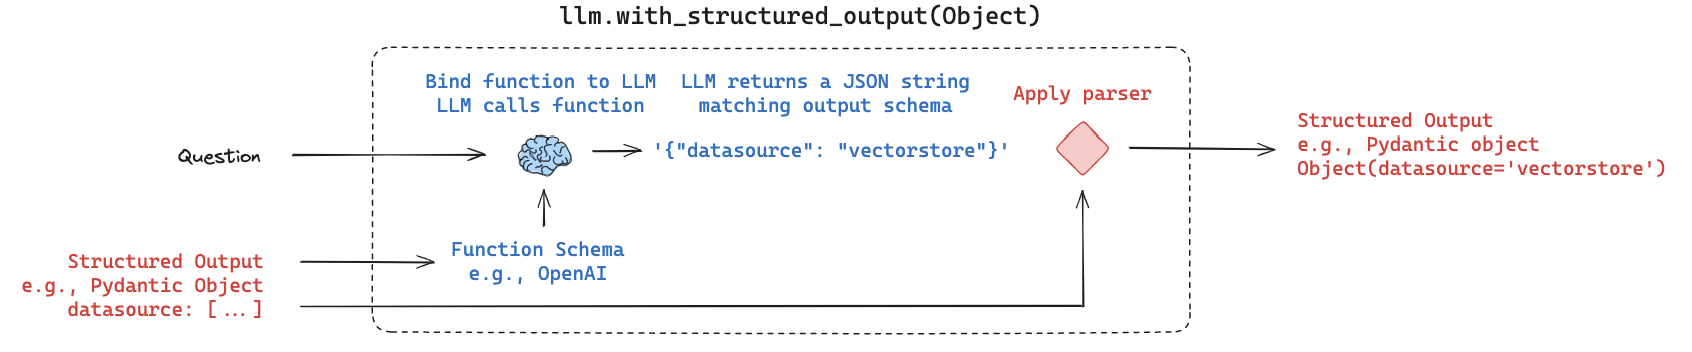

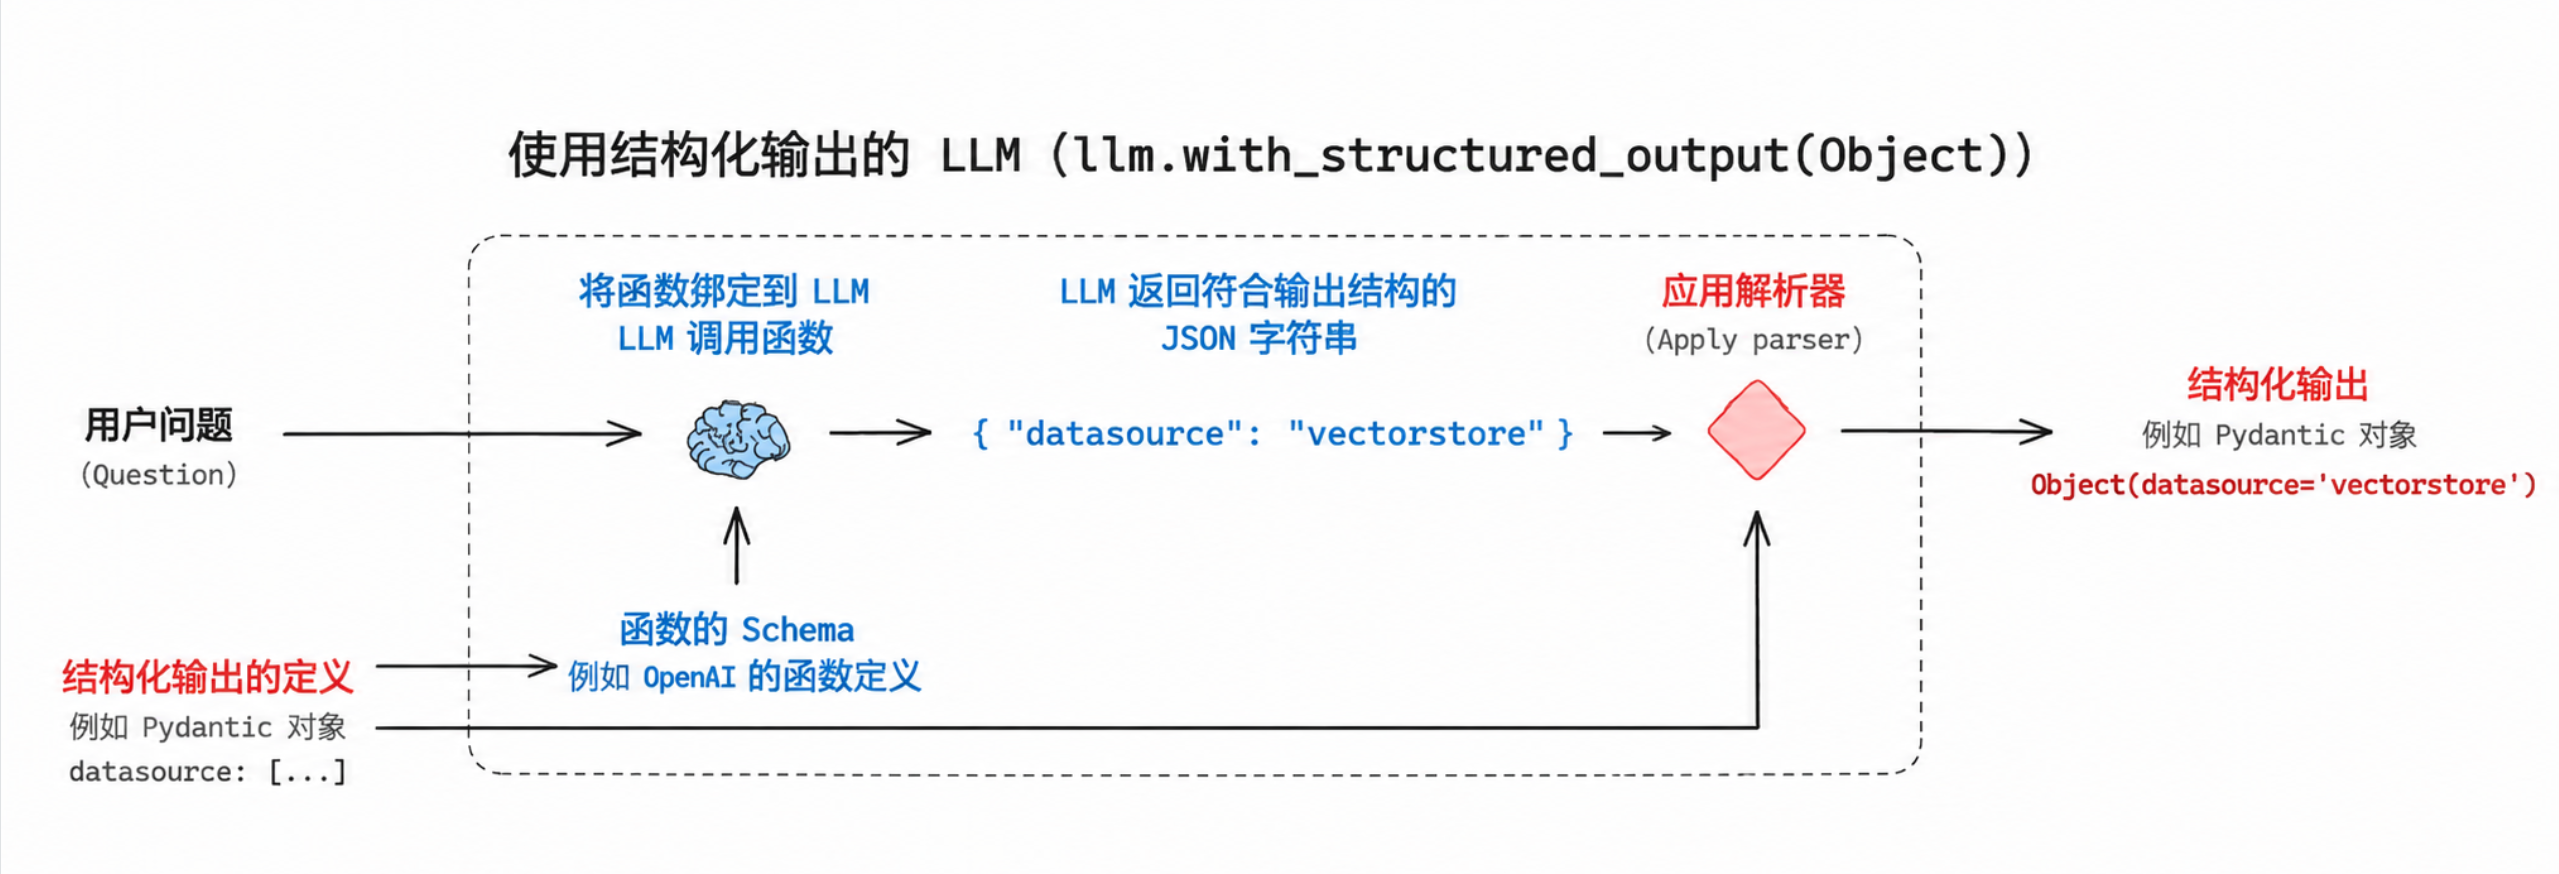

In [ ]:
# 通过router链（路由规则），llm会输出到底选择哪个库

question = """Why doesn't the following code work:

from langchain_core.prompts import ChatPromptTemplate

prompt = ChatPromptTemplate.from_messages(["human", "speak in {language}"])
prompt.invoke("french")
"""
# router = prompt | structured_llm 
# router就是一个链，

result = router.invoke({"question": question})

print(result)
print(type(result))  # Pydantic 对象
print(result.datasource)



datasource='python_docs'
<class '__main__.RouteQuery'>
python_docs


一旦我们获得了这个结构化结果，就可以很容易地定义一个分支，根据 result.datasource 的值选择对应的处理路径。



In [ ]:
# router.invoke() 是只执行分类；
# full_chain.invoke() 是执行分类之后，自动接着执行路由判断。

from langchain_core.runnables import RunnableLambda

def choose_route(result):
    # in :
    # 可以表示 一个大字符串里，有没有包含小的字符串
    if "python_docs" in result.datasource.lower():  #避免大小写不同导致判断失败
        ### Logic here 
        return "chain for python_docs"
    elif "js_docs" in result.datasource.lower():
        ### Logic here 
        return "chain for js_docs"
    else:
        ### Logic here 
        return "golang_docs"

# choose_route函数，经过RunnableLambda变成可以在管道运行的部件
# choose_route接收管道传来的router，作为自己的输入变量

# 完整的链：
# full_chain = prompt | structured_llm | RunnableLambda(choose_route)
full_chain = router | RunnableLambda(choose_route)

In [ ]:
# 根据问题选择路由

full_chain.invoke({"question": question})

'chain for python_docs'

Trace:

https://smith.langchain.com/public/c2ca61b4-3810-45d0-a156-3d6a73e9ee2a/r

### Semantic routing 语义路由

Flow:

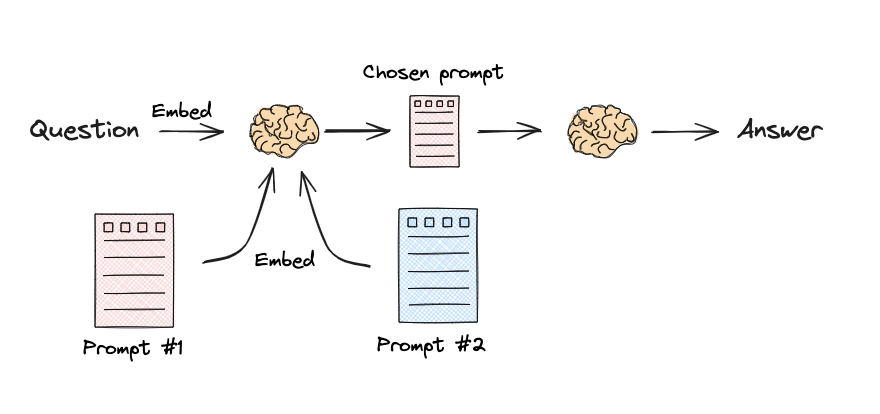

- Logical Routing 根据明确的规则进行分类；Semantic Routing 根据问题的语义相似度选择最合适的 Prompt 或处理链。

- Logical Routing会让llm选择一个库，他的prompt可能限制只能选那几样
- Semantic Routing 给出多种prompt模版，把问题和prompt全部embedding嵌入到向量空间，比较相似度

In [ ]:
# cosine_similarity 举例
from langchain_community.utils.math import cosine_similarity

prompt_embeddings = [
    [0.1, 0.2, 0.3, 0.4],  # Physics
    [0.5, 0.6, 0.7, 0.8]   # Math
]

query_embedding = [0.2, 0.3, 0.4, 0.5]

# cosine_similarity(X, Y) ：计算 X 中每一条向量 和 Y 中每一条向量 的余弦相似度
# 要求输入是二维数组，而且最后一维必须相同
# 输出一定是二维数组，shape = (n_samples_X, n_samples_Y)，行列数是XY的样本数
similarity_raw = cosine_similarity(
    [query_embedding],  #    1x4   [ [0.2, 0.3, 0.4, 0.5] ] 
    prompt_embeddings   #    2x4
) # 1x2

In [ ]:
from langchain_community.utils.math import cosine_similarity
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import PromptTemplate
from langchain_core.runnables import RunnableLambda, RunnablePassthrough
from rag_config import make_chat_model, make_embeddings

# Two prompts
# 物理问题
physics_template = """你是一名学识渊博的物理学教授。你擅长简洁通俗地解答物理相关问题。如果不知道答案，就如实承认自己不懂。

问题如下：
{query}"""

#数学问题
math_template = """你是一名优秀的数学家。你十分擅长解答数学问题。你擅长把难题拆解成多个小部分，逐个解决，再整合结果，最终回答原题。

问题如下：
{query}"""

# Embed prompts
embeddings = make_embeddings()
prompt_templates = [physics_template, math_template]
prompt_embeddings = embeddings.embed_documents(prompt_templates) # list[list[float]]嵌套list也可被转化为二维矩阵

# Route question to prompt 
def prompt_router(input):
    # Embed question
    query_embedding = embeddings.embed_query(input["query"])

    # 由于cosine_similarity() 要求两个参数都可以被转化为二维结构，所以需要给 query_embedding 加一层中括号，query_embedding变成一个二维矩阵里面的一行。
    similarity_raw = cosine_similarity([query_embedding], prompt_embeddings) 
    similarity = similarity_raw[0]  # 提取一行，提取第一个X样本对应的它和Y的全部样本的相似度

    print(similarity_raw,similarity_raw.shape)
    print(similarity,similarity.shape) 

    # cosine_similarity() 按矩阵顺序计算计算相似度，不负责排序

    # argmax()返回最大值所在的位置（索引）
    #把向量形式映射到真实的prompt字符串
    most_similar = prompt_templates[similarity.argmax()] 
    print("选择：",most_similar)

    # Chosen prompt 
    print("选择Using MATH" if most_similar == math_template else "选择Using PHYSICS")

    return PromptTemplate.from_template(most_similar)


chain = (
    {"query": RunnablePassthrough()} # 输入不是字典，而是字符串，所以用原样返回传来的值
    # RunnableLambda：把普通 Python 函数包装成 Runnable对象

    #先执行prompt_router(input)，返回一个待填充的PromptTemplate类型
    #如果返回对象是Runnable的，那么RunnableLambda会自动执行这个返回的对象，用自己上层管道传入的数据再次传输给返回的对象。
    # 也就是query不仅要传给prompt_router(input)，还要传给他的返回值PromptTemplate.from_template(most_similar)
    | RunnableLambda(prompt_router)  
    | make_chat_model()
    | StrOutputParser()
)

print(chain.invoke("什么是黑洞"))  

[[0.30576572 0.17963889]] (1, 2)
[0.30576572 0.17963889] (2,)
选择： 你是一名学识渊博的物理学教授。你擅长简洁通俗地解答物理相关问题。如果不知道答案，就如实承认自己不懂。

问题如下：
{query}
选择Using PHYSICS
你好！作为一名物理学教授，我很乐意用最通俗的方式为你解释“黑洞”。

简单来说，**黑洞是宇宙中引力强到连光都无法逃脱的区域。**

你可以把它想象成一个**“时空陷阱”**：

1.  **它是怎么形成的？**
    通常是由一颗质量巨大的恒星在生命尽头发生坍缩形成的。当物质被压缩到一个极小的空间里，它的密度变得无限大，引力也就变得无限强。

2.  **为什么叫“黑”洞？**
    因为它的引力太强了，任何靠近它的东西——包括我们看到的**光**——都会被吸进去，再也跑不出来。既然没有光能反射或发射出来，我们的眼睛（或望远镜）就看不见它，所以它是“黑”的。

3.  **关键概念：事件视界（Event Horizon）**
    这是黑洞的“边界”，就像一条单行道。一旦你跨过这条线，无论你怎么努力，都永远无法返回外部宇宙。这也是黑洞最神秘的地方。

4.  **它不是“吸尘器”**
    很多人误以为黑洞会像宇宙吸尘器一样把远处的星星都吸走。其实不会！如果你把太阳换成一个同等质量的黑洞，地球并不会被吸进去，而是会继续绕着它公转（只是我们会陷入黑暗和寒冷）。只有当你靠得足够近，进入它的强大引力范围时，才会被吞噬。

**总结一下：**
黑洞就是宇宙中一个**引力极端强大、连光都逃不掉**的天体区域。它是爱因斯坦广义相对论预言的最奇特现象之一，也是现代天体物理学的研究热点。

希望这个解释清晰易懂！如果你对某个细节感兴趣，欢迎继续提问。


# Rag From Scratch: Query Construction 构造查询

用户使用`自然语言提问`，但是数据库需要结构化的`SQL语句或SQL条件`

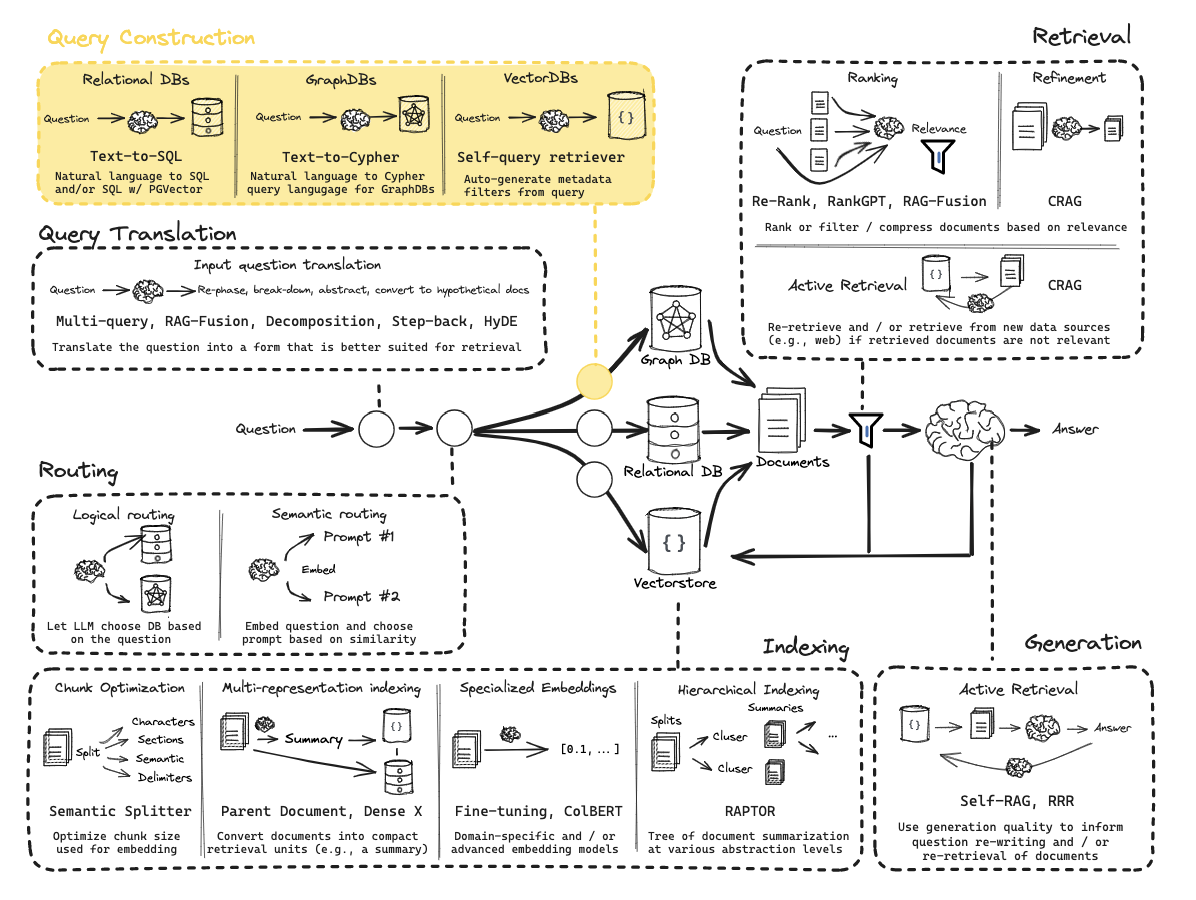



## metadata filters  元数据过滤

Flow:

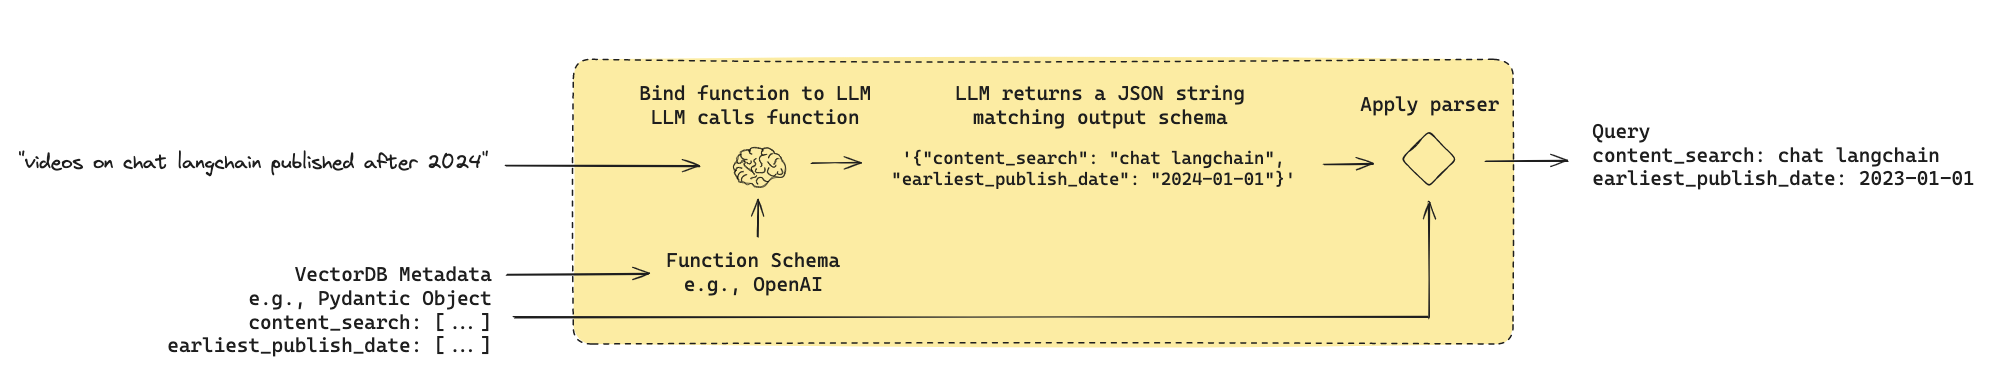

Many vectorstores contain metadata fields. 

很多向量数据库都带有元数据字段。

This makes it possible to filter for specific chunks based on metadata.

借助元数据，我们可以根据它筛选出特定的文本块。

## 爬一个b站视频
- cookie需要从F12应用程序里面每隔一段时间更新
- 下面的代码没有用到这个视频，B 站视频就是用来构建向量库的原始数据。


In [33]:
from langchain_community.document_loaders import BiliBiliLoader

# 从浏览器F12拿到这三个cookie
SESSDATA = "5ed77e2b%2C1808975065%2C1de49%2Aa2CjD8jsRkPpKHsqoZGPUlO7nv-6ArtbhyLSLpeB_tWCzrWOFtqwb4ZNdUa5hYQJDgf2sSVmNvNVdHc0FvRVFJQU1rVnBaWlFRN29QNER4Q0JOY3Y1LW5XU3M2cGhGbGVPbXlxRWkwMGRCdkRoSmJobmxYd2JmbkVQLTY0cTUtUGFZengzcExBRjhnIIEC"
BILI_JCT = "947bb24b5e5bb13cad08cb95084c8e87"
BUVID3 = "33885371-F4CC-3707-A5DF-D18EE3B41E1D11234infoc"

loader = BiliBiliLoader(
    video_urls=["https://www.bilibili.com/video/BV1jGpP6cEii/"],
    sessdata=SESSDATA,
    bili_jct=BILI_JCT,
    buvid3=BUVID3
)
docs = loader.load()
print(docs[0].page_content) # 字幕文本
print(docs[0].metadata)     # 标题、UP主、封面、发布时间等元信息


Video Title: 10分钟带你理解Transformer, description: 自用

Transcript: Cheat gp t cloud deep seek 这些会聊天 会写代码的大模型背后几乎都是同一种结构 他叫transformer 出自2017年谷歌的一篇论文 Attention is all you need 这个视频 我们从零开始 一步一步把它拆开 看完你会明白文字怎么变成数字 字与字之间怎么交流 以及模型怎么一个字一个字的写出回答 先说清楚语言模型到底在做什么 其实只有一件事 根据前面的文字预测下一个字 比如输入今天天气很 模型会给每个可能的下一个字打分 这是一个真实的中文 GPT2模型给出的概率好排在第一 把选出来的字接到末尾再预测下一个 如此循环就能写出一整段话 在transformer之前 主流做法是循环神经网络 也就是RNM 他像传话游戏一样 一个字一个字的把信息往后传 句子一长 开头的信息就越传越模糊 而且必须排队计算 没法并行 transformer的想法很直接 别排队了 让每个字直接看到所有其他字 这个看的机制就叫做注意力 第一步把文字变成模型 能处理的数字文本先被切成一个个小单元 叫做token 中文叫词源 每个token都有一个编号 就像他在一本巨大词典里的页码模型 用这个编号去查一张表 取出一串数字 也就是一个向量 这一步叫做词嵌入 你可以把每个向量想象成空间里的一个点 训练之后意思相近的词会靠在一起 猫和狗挨着 苹果和香蕉挨着 更神奇的是 方向也有含义 从男人到女人的方向 和从国王到女王的方向几乎一样 当然真实模型的向量有几百上千维 这里只是把它画在了二维平面上 不过这里有个问题 注意力机制本身不看顺序 猫追狗和狗追猫在他眼里是同一堆字 所以我们要给每个位置一个独一无二的坐标 直接加到磁向量上 原论文用的是一组频率 各不相同的正弦和余弦波 每一行是一个位置的编码 左边的维度变化快 右边的变化慢 就像钟表上的秒针 分针和时针 这样一来模型既知道每个字是什么 也知道他排在第几 接下来是transformer最核心的部分 自注意力看这句话 猫没有过马路 因为它太累了 这里的他指的是谁 你一眼就知道是猫 可模型怎么知道呢 办法是让他去问一问句子里的每一个字 为此每个token会生成三个向量 Query key和valu

In [ ]:
print(docs[0].metadata.keys())

print(docs[0].metadata)  # 目前获得的元数据

dict_keys(['bvid', 'aid', 'videos', 'tid', 'tid_v2', 'tname', 'tname_v2', 'copyright', 'pic', 'title', 'pubdate', 'ctime', 'desc', 'desc_v2', 'state', 'duration', 'rights', 'owner', 'stat', 'argue_info', 'dynamic', 'cid', 'dimension', 'premiere', 'teenage_mode', 'is_chargeable_season', 'is_story', 'is_upower_exclusive', 'is_upower_play', 'is_upower_preview', 'enable_vt', 'vt_display', 'is_upower_exclusive_with_qa', 'is_hua_sheng', 'no_cache', 'pages', 'subtitle', 'is_season_display', 'user_garb', 'honor_reply', 'like_icon', 'need_jump_bv', 'disable_show_up_info', 'is_story_play', 'is_view_self', 'url'])
{'bvid': 'BV1jGpP6cEii', 'aid': 117394777378914, 'videos': 1, 'tid': 231, 'tid_v2': 2096, 'tname': '', 'tname_v2': '', 'copyright': 3, 'pic': 'http://i0.hdslb.com/bfs/archive/221a4f68b673053948e57c6930c58fa29f9c6899.jpg', 'title': '10分钟带你理解Transformer', 'pubdate': 1791302271, 'ctime': 1791302271, 'desc': '自用', 'desc_v2': [{'raw_text': '自用', 'type': 1, 'biz_id': 0}], 'state': 0, 'duratio

## Self‑Query Retriever（自查询检索）

- 此处只是在构建查询转换器，让llm自己查数据，还没有Self‑Query，只是他的前置工作

普通向量检索：只拿整句话做 embedding，**只能靠语义相似度召回**，分不清结构化条件。

Self-Query 的核心是：LLM 帮你 “拆查询”

- `query`：用来做向量相似度检索的文本（语义部分）
- `filter`：给向量库的元数据过滤规则（结构化条件）

假设我们已经建立了一个索引（Index），它具有以下功能：
1. **支持非结构化搜索（Unstructured Search）**：对contents（内容），title（标题）进行语义或文本搜索。
2. **支持范围过滤（Range Filtering）**：根据 view count、publication date和 length进行筛选。

我们希望将用户的自然语言转换成结构化的搜索查询（Structured Search Queries）。
```
用户自然语言
      ↓
LLM 理解问题
      ↓
拆分成两类条件
      ├── 语义检索：Transformer
      │
      └── Metadata Filter：
           view_count >= 1000
           duration_sec <= 900
```
我们可以为结构化搜索查询定义一个数据结构`（Schema）`。

以下，假设用户提出：
- 帮我找 LangChain 教程视频：
- 发布时间在 2024 年之后
- 视频时长不超过 20 分钟

期望能够让llm自己提取出来相关信息，比如：
```bash
{
    "content_search": "LangChain tutorial",
    "title_search": "LangChain tutorial",
    "min_view_count": 10000,
    "max_view_count": None,
    "earliest_publish_date": "2024-01-01",
    "latest_publish_date": None,
    "min_length_sec": None,
    "max_length_sec": 1200
}
```

## 结构化查询结果
提前规定：
LLM 最终应该输出哪些字段，每个字段是什么类型，有什么含义。


In [36]:
import datetime
from typing import Literal, Optional, Tuple  # Optional:表示字段可以是指定类型，也可以是 None
from pydantic import BaseModel, Field

class TutorialSearch(BaseModel): # 查询教程
    """在 Bilibili 教程视频数据库中进行搜索。"""

    # 必填字段，告诉llm我要搜索什么
    content_search: str = Field(
        ...,
        description="应用于视频字幕文本的相似度搜索查询,根据里面的内容查找相关的视频",
    )
    title_search: str = Field(
        ...,
        # Python 里，括号里放多个相邻字符串字面量，会自动拼接成一个字符串
        description=(
            "将内容搜索查询改写成另一个版本，用于搜索视频标题，"
            "将 content_search 改写成适合搜索视频标题的简短关键词，只保留可能出现在视频标题中的关键词。"
        ),
    )

    # 选填字段，如果用户没问，就不用提取
    min_view_count: Optional[int] = Field(
        None,  # 这个字段不是必填的，如果用户没有提出播放量要求，就不需要设置它。
        description="Minimum view count filter, inclusive. Only use if explicitly specified.",
    )
    max_view_count: Optional[int] = Field(
        None,                     #exclusive：不包含边界值，严格大于或小于。
        description="Maximum view count filter, exclusive. Only use if explicitly specified.",
    )
    earliest_publish_date: Optional[datetime.date] = Field(
        None,                    # inclusive：包含边界值，≥ 或 ≤
        description="Earliest publish date filter, inclusive. Only use if explicitly specified.",
    )
    latest_publish_date: Optional[datetime.date] = Field(
        None,
        description="Latest publish date filter, exclusive. Only use if explicitly specified.",
    )
    min_length_sec: Optional[int] = Field(
        None,
        description="Minimum video length in seconds, inclusive. Only use if explicitly specified.",
    )
    max_length_sec: Optional[int] = Field(
        None,
        description="Maximum video length in seconds, exclusive. Only use if explicitly specified.",
    )

    # 打印有实际值的字段,忽略 None 和默认值。
    def pretty_print(self) -> None:
        for field in type(self).model_fields:
            value = getattr(self, field)

            if value is not None:
                print(f"{field}: {value}")

Now, we prompt the LLM to produce queries.

In [ ]:
from langchain_core.prompts import ChatPromptTemplate
from rag_config import make_chat_model

system = """你是一名擅长把用户问题转化为数据库查询语句的专家。
你可以访问一个教程视频数据库,里面的视频讲解10分钟带你理解Transformer。
给定一个问题，返回经过优化的数据库查询，用来获取最相关的结果。
如果遇到不熟悉的缩写或词汇，不要擅自改写"""
prompt = ChatPromptTemplate.from_messages(
    [
        ("system", system),
        ("human", "{question}"),  # invoke进来的用户提问
    ]
)
llm = make_chat_model(temperature=0)

# 结构化输出，就是处理llm的输出，强制为指定类 TutorialSearch
structured_llm = llm.with_structured_output(
    TutorialSearch, 
    method="function_calling")

query_analyzer = prompt | structured_llm

In [ ]:
information=query_analyzer.invoke({"question": "找一个讲解Transformer的视频,播放量超过1000,时长不超过15分钟"})

print(information)  # 是TutorialSearch类
print()
information.pretty_print()  # 以上代码的目的就是生成这样的检索条件，好让llm能够接下来自查询检索的时候，去向量库里面找符合条件的视频

content_search='Transformer 讲解 原理 结构' title_search='Transformer 讲解' min_view_count=1000 max_view_count=None earliest_publish_date=None latest_publish_date=None min_length_sec=None max_length_sec=900

content_search: Transformer 讲解 原理 结构
title_search: Transformer 讲解
min_view_count: 1000
max_length_sec: 900


In [51]:
query_analyzer.invoke(
    {"question": "videos on chat langchain published in 2023"}
).pretty_print()

content_search: chat langchain tutorial
title_search: langchain chat
earliest_publish_date: 2023-01-01
latest_publish_date: 2024-01-01


In [52]:
query_analyzer.invoke(
    {"question": "videos that are focused on the topic of chat langchain that are published before 2024"}
).pretty_print()

content_search: chat langchain tutorial
title_search: chat langchain
latest_publish_date: 2024-01-01


In [53]:
query_analyzer.invoke(
    {
        "question": "how to use multi-modal models in an agent, only videos under 5 minutes"
    }
).pretty_print()

content_search: 多模态模型在智能体中的应用，如何使用多模态模型构建Agent
title_search: 多模态 Agent 智能体
max_length_sec: 300


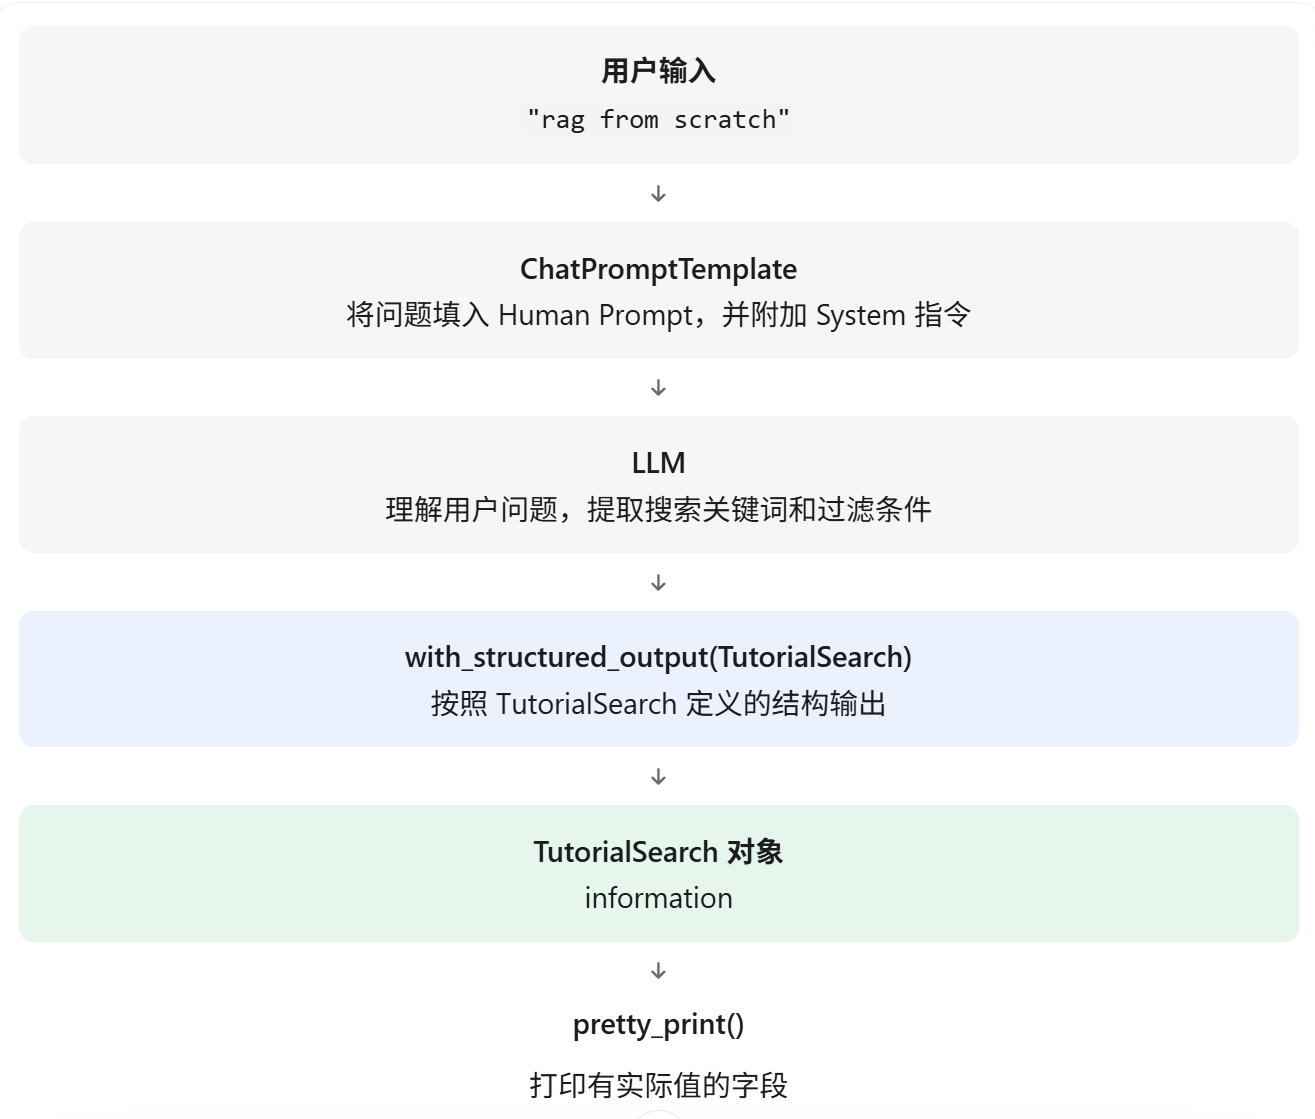